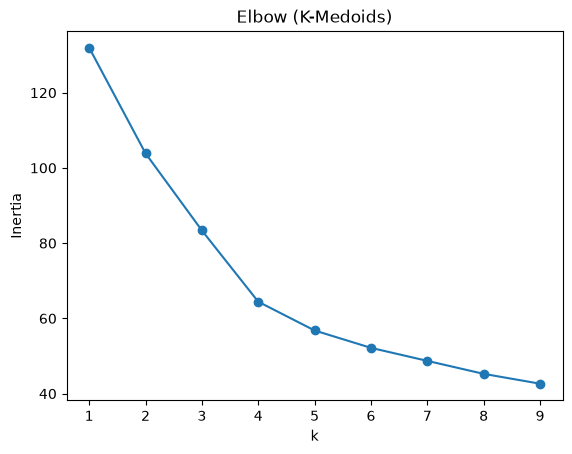

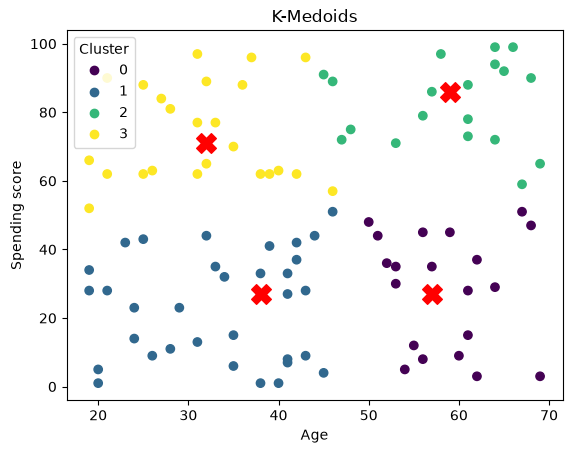

          age  spending_score
Cluster                      
0        58.4            28.2
1        33.5            23.5
2        59.0            82.8
3        31.6            73.7


In [1]:
# ===================== REVISION / ONE-SHOT: K-MEDOIDS =====================
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids

# 1) Random data in a DataFrame
np.random.seed(42)
df = pd.DataFrame({"age": np.random.randint(18, 70, 100),
                   "spending_score": np.random.randint(1, 100, 100)})

# 2) Scale (distance based method)
X = StandardScaler().fit_transform(df)

# 3) Elbow on inertia_ (sum of distances to medoids)
cost = [KMedoids(n_clusters=k, random_state=42).fit(X).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), cost, marker="o"); plt.title("Elbow (K-Medoids)"); plt.xlabel("k"); plt.ylabel("Inertia"); plt.show()

# 4) Fit final model
model = KMedoids(n_clusters=4, random_state=42)
df["Cluster"] = model.fit_predict(X)
medoids = df.iloc[model.medoid_indices_]        # medoids are REAL rows of the data

# 5) Plot clusters + medoids
sc = plt.scatter(df["age"], df["spending_score"], c=df["Cluster"], cmap="viridis")
plt.scatter(medoids["age"], medoids["spending_score"], c="red", marker="X", s=200, label="Medoids")
plt.legend(*sc.legend_elements(), title="Cluster"); plt.title("K-Medoids"); plt.xlabel("Age"); plt.ylabel("Spending score"); plt.show()

# 6) Summary per segment
print(df.groupby("Cluster").mean().round(1))

# ---------------- VIVA NOTES ----------------
# K-Medoids picks actual data points (medoids) as centres, K-Means uses mean points (centroids).
# Minimizes sum of distances (not squared), so it is robust to outliers.
# Can use any distance metric (metric="manhattan", "euclidean", ...).
# Key params: n_clusters, metric, method ("alternate" fast, "pam" more accurate), random_state.
# Import: from sklearn_extra.cluster import KMedoids (package scikit-learn-extra).
# Read plot: each colour = segment, red X = medoid (most representative real customer/area).

### Q9

Generate a random dataset of urban areas with features such as population density, average income, and amenities, (min. 100 data). Apply K-medoids clustering to identify neighbourhoods with similar characteristics. Visualize the clusters on a map.

In [2]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids

In [3]:
# Random urban areas: 150 rows, plus random latitude/longitude for the map
np.random.seed(42)
n = 150
df = pd.DataFrame({
    "population_density": np.random.randint(500, 20000, n),   # people per sq km
    "avg_income": np.random.randint(15000, 150000, n),         # yearly income
    "amenities": np.random.randint(1, 50, n),                  # parks, schools, shops ...
    "latitude": np.random.uniform(22.95, 23.15, n),            # random city area
    "longitude": np.random.uniform(72.45, 72.70, n),
})
print(df.head())
print("Shape:", df.shape)

   population_density  avg_income  amenities   latitude  longitude
0               16295       83840         20  23.137330  72.678291
1                1360      133451          1  22.957837  72.596287
2                5890       66005          8  23.033589  72.631530
3               12464       54353         46  23.143516  72.639270
4               11784       67733         16  23.059594  72.544463
Shape: (150, 5)


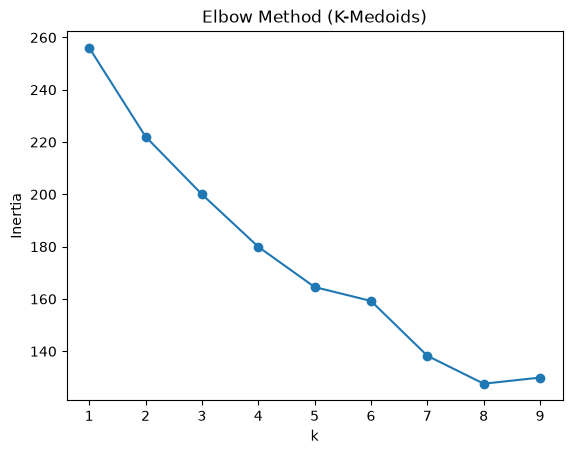

In [4]:
# Cluster on the 3 features only (location is just for plotting), scale first
features = ["population_density", "avg_income", "amenities"]
X = StandardScaler().fit_transform(df[features])

# Elbow to choose k
cost = [KMedoids(n_clusters=k, random_state=42).fit(X).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), cost, marker="o")
plt.title("Elbow Method (K-Medoids)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

In [5]:
# Fit K-Medoids with k = 4
model = KMedoids(n_clusters=4, random_state=42)
df["Cluster"] = model.fit_predict(X)
print(df["Cluster"].value_counts())

Cluster
2    49
1    42
3    36
0    23
Name: count, dtype: int64


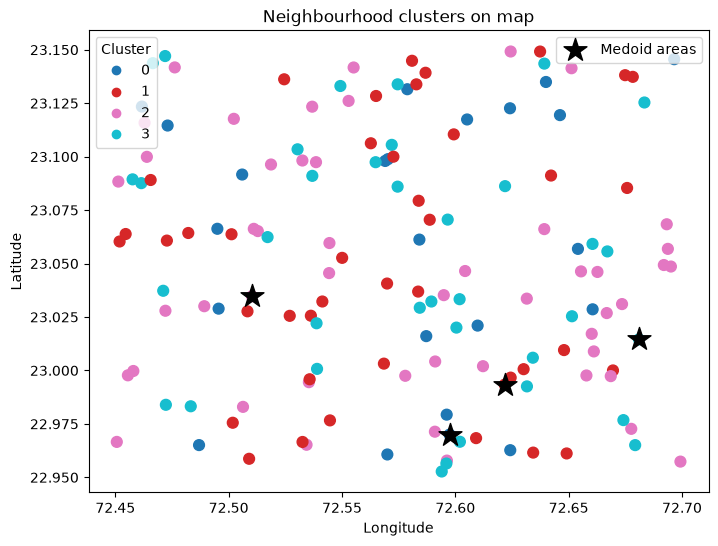

In [6]:
# Map: longitude on x, latitude on y, coloured by cluster
medoids = df.iloc[model.medoid_indices_]
plt.figure(figsize=(8, 6))
sc = plt.scatter(df["longitude"], df["latitude"], c=df["Cluster"], cmap="tab10", s=60)
plt.scatter(medoids["longitude"], medoids["latitude"], c="black", marker="*", s=300, label="Medoid areas")
leg = plt.legend(*sc.legend_elements(), title="Cluster", loc="upper left")
plt.gca().add_artist(leg)            # keep cluster legend when adding a second one
plt.legend(loc="upper right")
plt.title("Neighbourhood clusters on map")
plt.xlabel("Longitude")
plt.ylabel("Latitude")
plt.show()

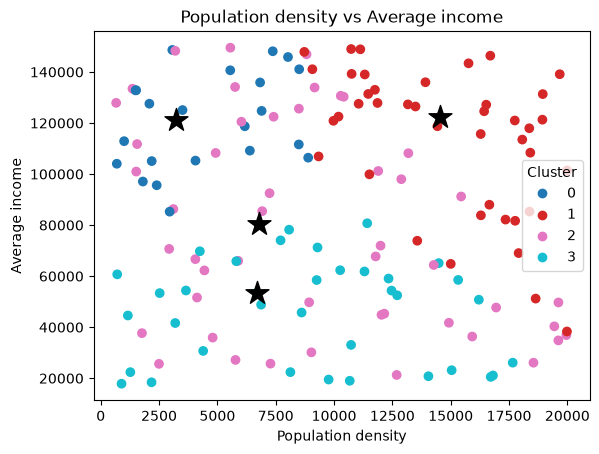

In [7]:
# Feature view: density vs income
sc = plt.scatter(df["population_density"], df["avg_income"], c=df["Cluster"], cmap="tab10")
plt.scatter(medoids["population_density"], medoids["avg_income"], c="black", marker="*", s=300, label="Medoids")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("Population density vs Average income")
plt.xlabel("Population density")
plt.ylabel("Average income")
plt.show()

In [8]:
# Summary of each neighbourhood type
print(df.groupby("Cluster")[features].mean().round(1))

         population_density  avg_income  amenities
Cluster                                           
0                    4484.5    120674.5       34.9
1                   14805.1    114179.2       27.8
2                    9061.7     78496.0        9.7
3                    8961.3     46128.7       34.9


### Q10

Generate a random dataset containing customer information (e.g., age, spending score)(100 rows), apply K-medoids clustering to segment customers into distinct groups. Visualize the clusters and summarize the characteristics of each segment

In [9]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from sklearn.preprocessing import StandardScaler
from sklearn_extra.cluster import KMedoids

In [10]:
# Random customers: 100 rows
np.random.seed(42)
df = pd.DataFrame({
    "age": np.random.randint(18, 70, 100),
    "spending_score": np.random.randint(1, 100, 100),
})
print(df.head())
print(df.describe())

   age  spending_score
0   56              45
1   69              65
2   46              89
3   32              71
4   60               9
              age  spending_score
count  100.000000       100.00000
mean    43.350000        48.88000
std     14.904663        30.04417
min     19.000000         1.00000
25%     31.750000        27.00000
50%     42.000000        45.00000
75%     57.000000        73.50000
max     69.000000        99.00000


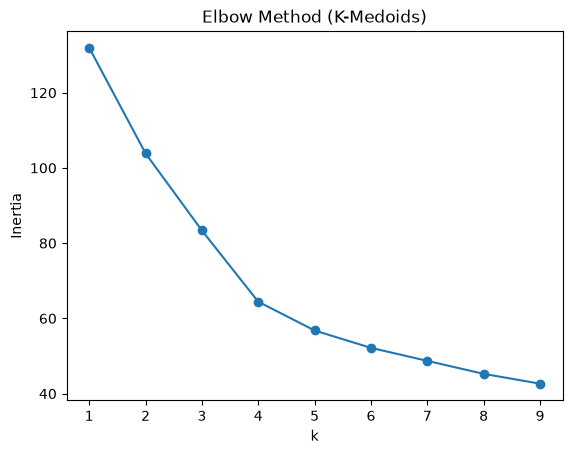

In [11]:
# Scale and choose k with elbow
X = StandardScaler().fit_transform(df)
cost = [KMedoids(n_clusters=k, random_state=42).fit(X).inertia_ for k in range(1, 10)]
plt.plot(range(1, 10), cost, marker="o")
plt.title("Elbow Method (K-Medoids)")
plt.xlabel("k")
plt.ylabel("Inertia")
plt.show()

In [12]:
# Fit K-Medoids with k = 4
model = KMedoids(n_clusters=4, random_state=42)
df["Cluster"] = model.fit_predict(X)
medoids = df.iloc[model.medoid_indices_]
print("Medoids (real customers):")
print(medoids)

Medoids (real customers):
    age  spending_score  Cluster
87   57              27        0
44   38              27        1
32   59              86        2
3    32              71        3


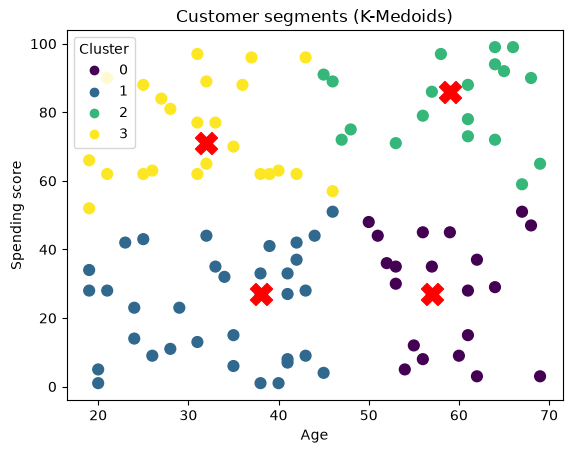

In [13]:
# Visualize segments
sc = plt.scatter(df["age"], df["spending_score"], c=df["Cluster"], cmap="viridis", s=60)
plt.scatter(medoids["age"], medoids["spending_score"], c="red", marker="X", s=250, label="Medoids")
plt.legend(*sc.legend_elements(), title="Cluster")
plt.title("Customer segments (K-Medoids)")
plt.xlabel("Age")
plt.ylabel("Spending score")
plt.show()

In [14]:
# Segment summary
summary = df.groupby("Cluster").agg(avg_age=("age", "mean"), avg_score=("spending_score", "mean"),
                                    count=("age", "size")).round(1)
print(summary)
# e.g. young + high score = trendy spenders, old + low score = careful buyers

         avg_age  avg_score  count
Cluster                           
0           58.4       28.2     21
1           33.5       23.5     34
2           59.0       82.8     20
3           31.6       73.7     25
